# Task 2 · Customer Segmentation Analysis

**Objective:** Group an e-commerce company's customers into distinct segments based on how they buy, so each group can get its own marketing approach.

**Dataset:** `Online_Retail.xlsx` (transactions from Dec 2010 to Dec 2011).



| Step | What we do |
|---|---|
| 1 | Load the data, inspect it, clean it |
| 2 | Descriptive statistics (purchase value, frequency, lifetime value) |
| 3 | Pick the behaviour features: Recency, Frequency, Monetary (RFM) |
| 4 | Standardise the features with `StandardScaler` |
| 5 | K-Means clustering, using the Elbow Method to choose K |
| 6 | Visualise the clusters with scatter plots |
| 7 | Profile each cluster |
| 8 | Bar chart of customers per cluster |
| 9 | Marketing recommendations for each segment |

*Needed packages: `pandas numpy scikit-learn matplotlib seaborn openpyxl`.*

## Step 1 · Load the data, inspect it, and clean it

First we load the file and look at its structure. Each row is **one product line on one invoice**, so a single order (invoice) has several rows.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42   # makes the clustering repeatable

In [2]:
df_raw = pd.read_excel("Online_Retail.xlsx")

print(f"Rows: {df_raw.shape[0]:,}  |  Columns: {df_raw.shape[1]}")
display(df_raw.head())
df_raw.info()

Rows: 541,909  |  Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


### Checking for missing and inconsistent data

Before analysing anything we look for rows that would give a wrong picture of customer behaviour. *(A row can appear in more than one line below, so these counts overlap.)*

In [3]:
quality = pd.DataFrame({
    "Issue": [
        "No CustomerID (can't be linked to a customer)",
        "No product Description",
        "Exact duplicate rows",
        "Cancelled invoices (InvoiceNo starts with 'C')",
        "Quantity is zero or negative (returns/adjustments)",
        "UnitPrice is zero or negative",
    ],
    "Rows": [
        df_raw["CustomerID"].isna().sum(),
        df_raw["Description"].isna().sum(),
        df_raw.duplicated().sum(),
        df_raw["InvoiceNo"].astype(str).str.startswith("C").sum(),
        (df_raw["Quantity"] <= 0).sum(),
        (df_raw["UnitPrice"] <= 0).sum(),
    ],
})
quality["% of all rows"] = (quality["Rows"] / len(df_raw) * 100).round(2)
display(quality)

,Issue,Rows,% of all rows
0,No CustomerID (can't be linked to a customer),135080,24.93
1,No product Description,1454,0.27
2,Exact duplicate rows,5268,0.97
3,Cancelled invoices (InvoiceNo starts with 'C'),9288,1.71
4,Quantity is zero or negative (returns/adjustme...,10624,1.96
5,UnitPrice is zero or negative,2517,0.46


**What this tells us:** about a quarter of the rows have no `CustomerID`. Segmentation is about *customers*, so rows we can't tie to a customer are useless here and are removed. We also remove duplicates, cancelled orders, and rows with zero or negative quantity or price, because they are not real purchases.

We also create `TotalPrice = Quantity x UnitPrice`, the value of each line.

In [4]:
df = df_raw.copy()
steps = [("Original data", len(df))]

df = df.dropna(subset=["CustomerID"])
steps.append(("Remove rows with no CustomerID", len(df)))

df = df.drop_duplicates()
steps.append(("Remove exact duplicate rows", len(df)))

df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df = df[~df["InvoiceNo"].str.startswith("C")]
steps.append(("Remove cancelled invoices", len(df)))

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
steps.append(("Remove Quantity or UnitPrice <= 0", len(df)))

df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

cleaning_log = pd.DataFrame(steps, columns=["Step", "Rows remaining"])
cleaning_log["Rows removed"] = (-cleaning_log["Rows remaining"].diff()).fillna(0).astype(int)
display(cleaning_log)

print(f"Clean data: {len(df):,} rows, {df['CustomerID'].nunique():,} customers, "
      f"{df['InvoiceNo'].nunique():,} orders")
print(f"Period covered: {df['InvoiceDate'].min():%d %b %Y} to {df['InvoiceDate'].max():%d %b %Y}")

,Step,Rows remaining,Rows removed
0,Original data,541909,0
1,Remove rows with no CustomerID,406829,135080
2,Remove exact duplicate rows,401604,5225
3,Remove cancelled invoices,392732,8872
4,Remove Quantity or UnitPrice <= 0,392692,40


Clean data: 392,692 rows, 4,338 customers, 18,532 orders
Period covered: 01 Dec 2010 to 09 Dec 2011


## Step 2 · Descriptive statistics

Three simple numbers describe how customers behave:

- **Average purchase value:** the average worth of one order (invoice), per customer.
- **Purchase frequency:** how many orders a customer placed.
- **Customer lifetime value (CLV):** here, the total amount a customer spent over the period. This is *historical* CLV, a simple and common version, not a forecast.

*Currency isn't stated. This is a UK retailer, so amounts are most likely pounds (£).*

In [5]:
order_values = df.groupby(["CustomerID", "InvoiceNo"])["TotalPrice"].sum()

customer = pd.DataFrame({
    "avg_purchase_value": order_values.groupby("CustomerID").mean(),
    "purchase_frequency": order_values.groupby("CustomerID").size(),
    "lifetime_value":     order_values.groupby("CustomerID").sum(),
})

summary = customer.describe().T.round(2)
summary.index = ["Average purchase value (per order)",
                 "Purchase frequency (orders per customer)",
                 "Customer lifetime value (total spend)"]
display(summary)

print(f"Typical (median) customer: {customer['purchase_frequency'].median():.0f} orders, "
      f"{customer['lifetime_value'].median():,.0f} total spend")
print(f"Average customer:          {customer['purchase_frequency'].mean():.1f} orders, "
      f"{customer['lifetime_value'].mean():,.0f} total spend")

,count,mean,std,min,25%,50%,75%,max
Average purchase value (per order),4338.0,417.65,1796.51,3.45,177.87,291.94,428.28,84236.25
Purchase frequency (orders per customer),4338.0,4.27,7.70,1.00,1.00,2.00,5.00,209.00
Customer lifetime value (total spend),4338.0,2048.69,8985.23,3.75,306.48,668.57,1660.60,280206.02


Typical (median) customer: 2 orders, 669 total spend
Average customer:          4.3 orders, 2,049 total spend


**What this tells us:** the *average* is well above the *median* (typical) customer for both frequency and spend. That means a small group of very heavy buyers pulls the average up. This matters later: it is the reason we transform the data before clustering.

## Step 3 · Feature selection: RFM analysis

To cluster customers we describe each one with just **three behaviour features**, the classic RFM set:

| Feature | Question it answers | How we measure it |
|---|---|---|
| **R**ecency | How recently did they buy? | Days since their last order (**lower = more recent = better**) |
| **F**requency | How often do they buy? | Number of orders |
| **M**onetary | How much do they spend? | Total spend |

Recency is measured from a "today" date set one day after the last transaction in the data.

In [6]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda s: (snapshot_date - s.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
)

print(f"Reference date for Recency: {snapshot_date:%d %b %Y}")
display(rfm.head())
display(rfm.describe().round(2))

Reference date for Recency: 10 Dec 2011


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


## Step 4 · Standardise the data

K-Means works by measuring **distances** between customers. The three features are on very different scales (Recency is in days, up to ~370; Monetary can reach tens of thousands). Without fixing this, Monetary would dominate. `StandardScaler` rescales each feature so it has an average of 0 and a spread of 1, giving all three an equal say.

**One extra step before scaling: a log transform.** Frequency and Monetary are heavily *skewed* (many small customers, a few giant ones). Extreme values would distort the clusters, so we first apply `log(1 + x)`, which compresses the long tail. Then we scale as required. 

,Skew (raw),Skew (after log)
Recency,1.25,-0.38
Frequency,12.07,1.21
Monetary,19.34,0.40


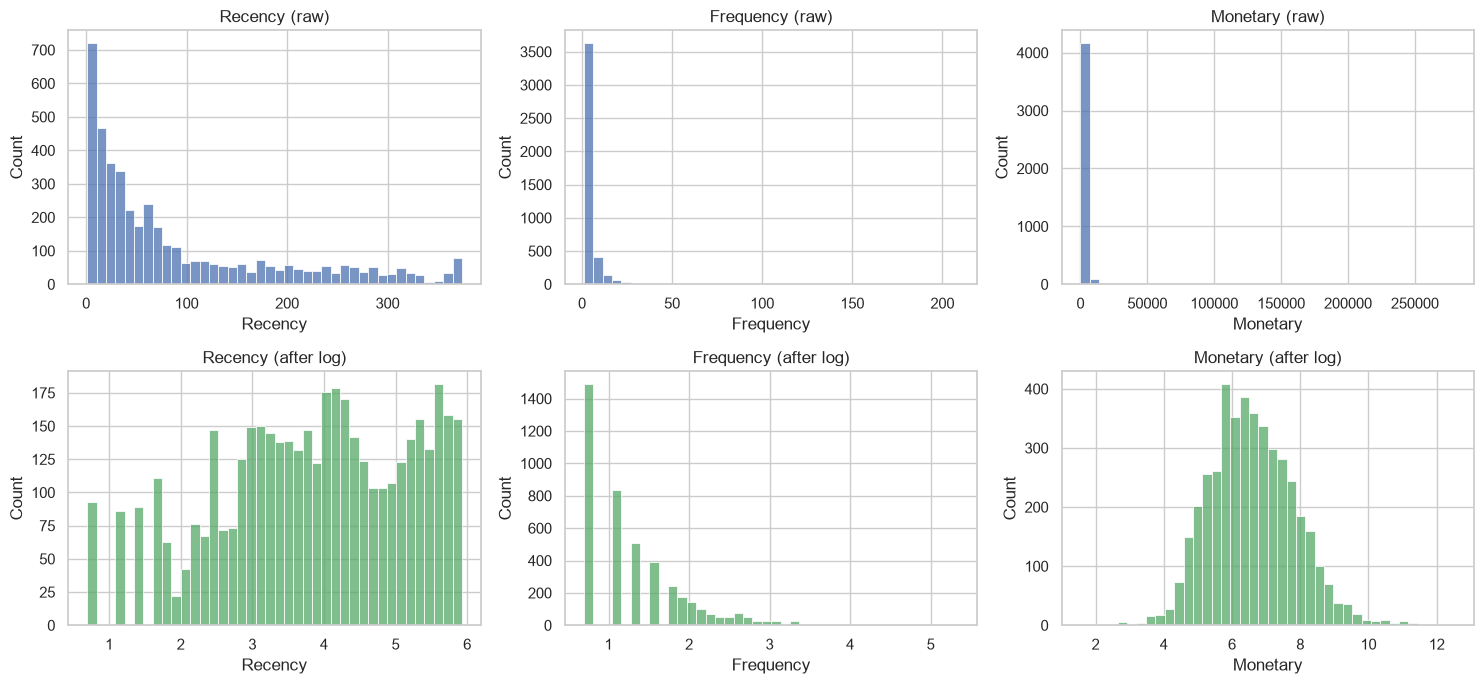

In [7]:
rfm_log = np.log1p(rfm)

skew = pd.DataFrame({"Skew (raw)": rfm.skew(), "Skew (after log)": rfm_log.skew()}).round(2)
display(skew)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(rfm.columns):
    sns.histplot(rfm[col], bins=40, ax=axes[0, i], color="#4c72b0")
    axes[0, i].set_title(f"{col} (raw)")
    sns.histplot(rfm_log[col], bins=40, ax=axes[1, i], color="#55a868")
    axes[1, i].set_title(f"{col} (after log)")
plt.tight_layout()
plt.show()

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

X_scaled_df = pd.DataFrame(X_scaled, index=rfm.index, columns=rfm.columns)
display(X_scaled_df.describe().loc[["mean", "std"]].round(2))

,Recency,Frequency,Monetary
mean,-0.0,-0.0,-0.0
std,1.0,1.0,1.0


**What this tells us:** the top row of charts shows the raw Frequency and Monetary values bunched up on the left with a long tail. After the log transform (bottom row) they are much more balanced. The scaled data now has a mean of 0 and a standard deviation of 1 for every feature, so it is ready for clustering.

## Step 5 · K-Means clustering and the Elbow Method

**K-Means** sorts customers into **K groups** so that customers within a group are as similar as possible. But we must tell it how many groups (K) to make.

The **Elbow Method** helps choose K. For each K we measure *inertia*: how spread out customers are inside their groups (lower = tighter groups). More groups always lowers inertia, so we look for the "elbow", the point where adding another group stops helping much.

As a second opinion we also compute the **silhouette score** (from -1 to 1; higher means the groups are better separated).

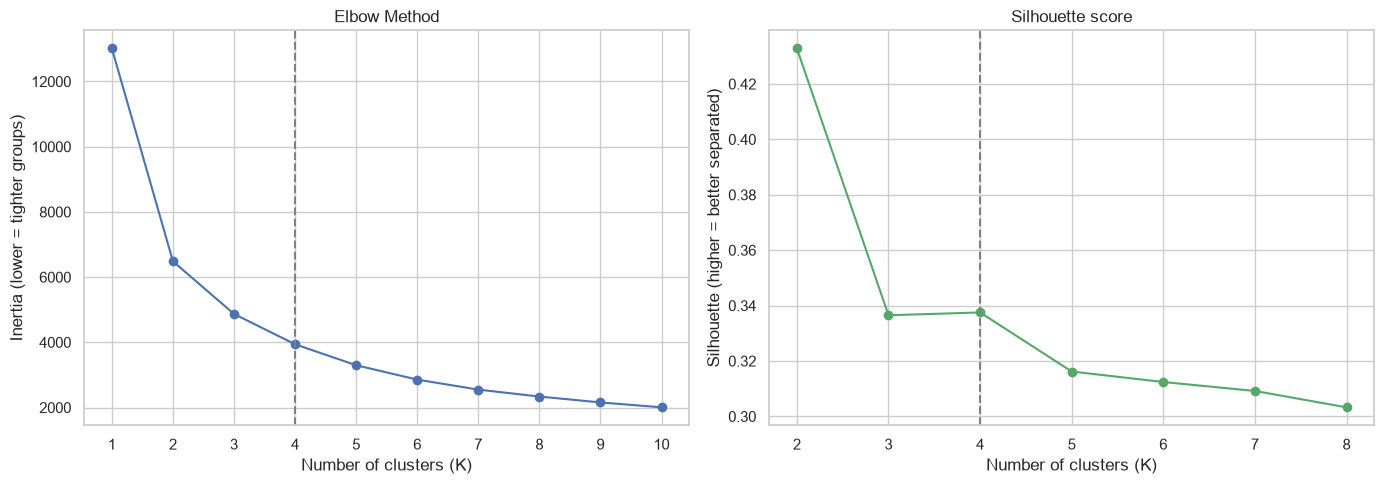

K,1,2,3,4,5,6,7,8,9,10
Inertia,13014.0,6484.0,4869.0,3939.0,3297.0,2856.0,2549.0,2336.0,2156.0,2006.0


K,2,3,4,5,6,7,8
Silhouette,0.433,0.337,0.338,0.316,0.312,0.309,0.303


In [9]:
k_range = range(1, 11)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled).inertia_
            for k in k_range]

sil_range = range(2, 9)
sil_scores = [silhouette_score(X_scaled,
                               KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled))
              for k in sil_range]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertias, marker="o", color="#4c72b0")
axes[0].axvline(4, ls="--", color="grey")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (lower = tighter groups)")
axes[0].set_xticks(list(k_range))

axes[1].plot(list(sil_range), sil_scores, marker="o", color="#55a868")
axes[1].axvline(4, ls="--", color="grey")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette (higher = better separated)")
axes[1].set_xticks(list(sil_range))

plt.tight_layout()
plt.show()

display(pd.DataFrame({"K": list(k_range), "Inertia": np.round(inertias, 0)}).set_index("K").T)
display(pd.DataFrame({"K": list(sil_range), "Silhouette": np.round(sil_scores, 3)}).set_index("K").T)

**Reading the charts and choosing K = 4**

- **Elbow:** the sharpest bend is at K = 2, and the curve keeps flattening gradually through K = 3 and K = 4. After about K = 4, extra groups add little.
- **Silhouette:** K = 2 scores highest, but it only splits customers into "good" and "the rest", which is too coarse for targeted marketing. K = 3 and K = 4 score almost the same.
- **Decision:** we use **K = 4**. It keeps the clusters well separated *and* gives four clearly different, actionable customer types. (K = 3 is a reasonable alternative; you can change `K` below and re-run everything after it.)

In [10]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
rfm["Cluster"] = kmeans.labels_

print(f"Final model: K = {K}, silhouette score = {silhouette_score(X_scaled, kmeans.labels_):.3f}")
print(rfm["Cluster"].value_counts().sort_index().to_string())

Final model: K = 4, silhouette score = 0.338
Cluster
0     713
1    1622
2     837
3    1166


### Giving each cluster a meaningful name

K-Means labels clusters 0, 1, 2, 3 in no particular order, which isn't helpful. After looking at each cluster's average behaviour, we name them by what they do. The rules below name them automatically: the top spenders are **Champions**, the group with the longest time since last order is **Lost / Dormant**, and of the other two, the bigger spenders are **Steady Regulars** and the smaller spenders are **Recent Low-Spenders**.

In [11]:
cluster_means = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()

names = {}
names[cluster_means["Monetary"].idxmax()] = "Champions"
lost = cluster_means["Recency"].idxmax()
if lost not in names:
    names[lost] = "Lost / Dormant"
rest = cluster_means.drop(index=list(names))
if len(rest) == 2:
    names[rest["Monetary"].idxmax()] = "Steady Regulars"
    names[rest["Monetary"].idxmin()] = "Recent Low-Spenders"
else:
    for c in rest.index:
        names[c] = f"Segment {c}"

rfm["Segment"] = rfm["Cluster"].map(names)

preferred = ["Champions", "Steady Regulars", "Recent Low-Spenders", "Lost / Dormant"]
present = list(rfm["Segment"].unique())
order = [s for s in preferred if s in present] + sorted(s for s in present if s not in preferred)

base_colors = {"Champions": "#2a9d8f", "Steady Regulars": "#457b9d",
               "Recent Low-Spenders": "#e9c46a", "Lost / Dormant": "#e76f51"}
fallback = sns.color_palette("Set2", K)
palette = {s: base_colors.get(s, fallback[i]) for i, s in enumerate(order)}

print(pd.Series(names).sort_index().rename("Segment name").to_string())

0              Champions
1         Lost / Dormant
2    Recent Low-Spenders
3        Steady Regulars


## Step 6 · Visualise the clusters

Each dot is one customer, coloured by segment. We show three feature combinations. Spend and order counts have a few huge values, so those axes use a **log scale** (each gridline is 10 times the previous one) to keep everyone visible.

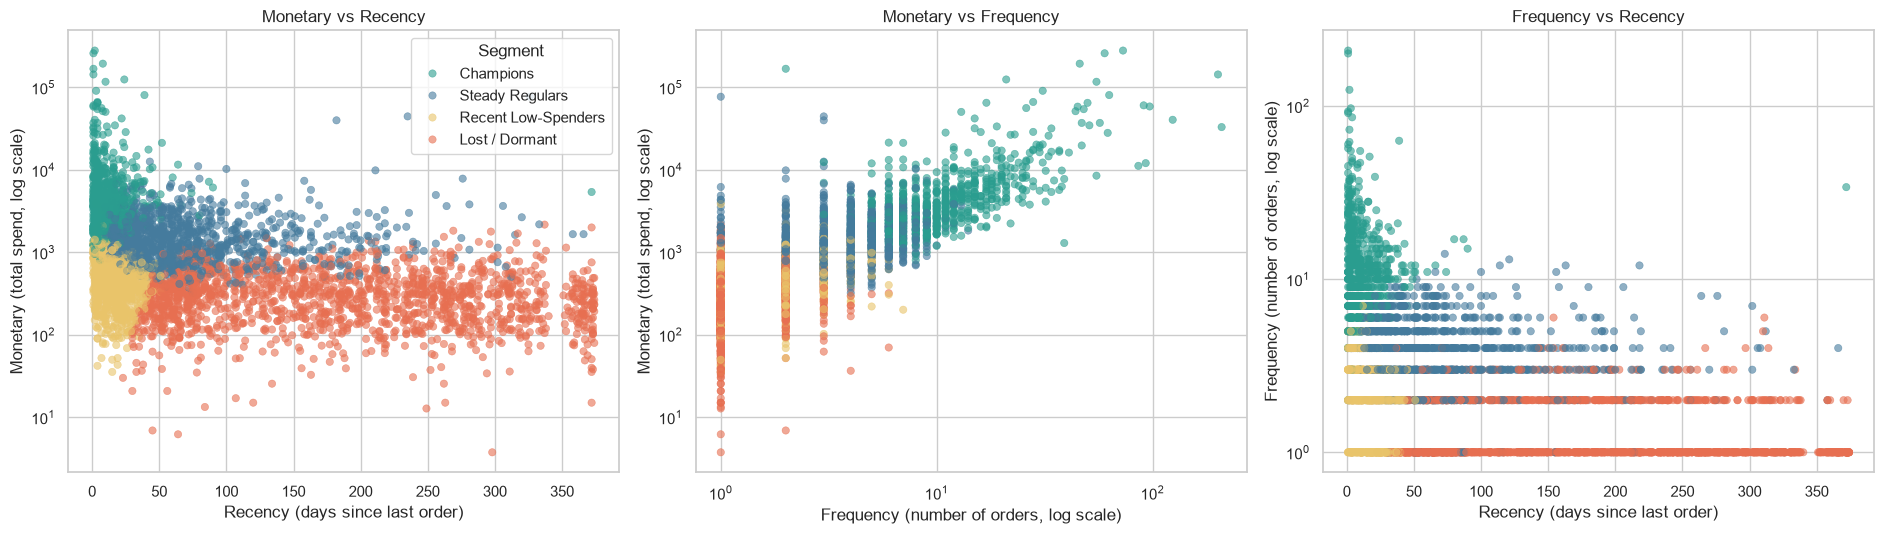

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

pairs = [("Recency", "Monetary"), ("Frequency", "Monetary"), ("Recency", "Frequency")]
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=rfm, x=x, y=y, hue="Segment", hue_order=order,
                    palette=palette, alpha=0.6, s=28, ax=ax, edgecolor=None)
    ax.set_yscale("log")
    if x == "Frequency":
        ax.set_xscale("log")
    ax.set_title(f"{y} vs {x}")
    if ax is not axes[0]:
        ax.get_legend().remove()

axes[0].legend(title="Segment", loc="upper right")
axes[0].set_xlabel("Recency (days since last order)")
axes[0].set_ylabel("Monetary (total spend, log scale)")
axes[1].set_xlabel("Frequency (number of orders, log scale)")
axes[1].set_ylabel("Monetary (total spend, log scale)")
axes[2].set_xlabel("Recency (days since last order)")
axes[2].set_ylabel("Frequency (number of orders, log scale)")

plt.tight_layout()
plt.show()

**How to read them:**

- **Left (Monetary vs Recency):** Champions sit at the top left (recent and high spend). Recent Low-Spenders sit at the bottom left (recent but small spend). Lost / Dormant customers sit to the right (long since their last order) with low spend. Steady Regulars fill the middle ground.
- **Middle (Monetary vs Frequency):** spend rises with order count, as you would expect. Champions occupy the upper right (many orders, high spend). The other segments overlap more here, because many customers have only 1 to 5 orders. That is why Recency is needed to tell them apart.
- **Right (Frequency vs Recency):** Recent Low-Spenders are recent with only 1 to 2 orders, Lost / Dormant customers are long gone with 1 to 2 orders, and Champions are recent with many orders.

Where colours meet, the borders are soft. That is normal for real customer data, because behaviour is a spectrum, not neat boxes.

## Step 7 · Profile each cluster

Now we describe what a typical customer in each segment looks like: the **mean** of each RFM feature, plus how big the segment is and how much revenue it brings in.

In [13]:
profile = rfm.groupby("Segment").agg(
    Customers=("Recency", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Revenue=("Monetary", "sum"),
).loc[order]

profile["% of customers"] = profile["Customers"] / profile["Customers"].sum() * 100
profile["% of revenue"] = profile["Revenue"] / profile["Revenue"].sum() * 100

display(profile.round(1).rename(columns={
    "Recency": "Avg Recency (days)",
    "Frequency": "Avg Frequency (orders)",
    "Monetary": "Avg Monetary (spend)",
    "Revenue": "Total revenue",
}))

,Customers,Avg Recency (days),Avg Frequency (orders),Avg Monetary (spend),Total revenue,% of customers,% of revenue
Segment,,,,,,,
Champions,713,12.2,13.8,8088.0,5766757.1,16.4,64.9
Steady Regulars,1166,71.6,4.1,1801.8,2100873.0,26.9,23.6
Recent Low-Spenders,837,17.7,2.2,557.3,466479.0,19.3,5.2
Lost / Dormant,1622,181.5,1.3,341.0,553099.8,37.4,6.2


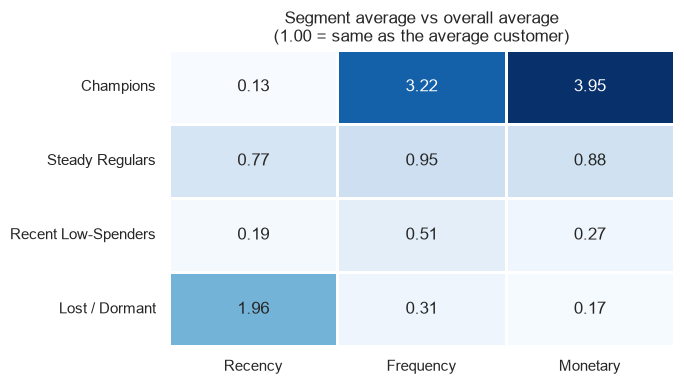

In [14]:
overall = rfm[["Recency", "Frequency", "Monetary"]].mean()
relative = profile[["Recency", "Frequency", "Monetary"]] / overall

plt.figure(figsize=(7, 4))
sns.heatmap(relative, annot=True, fmt=".2f", cmap="Blues", cbar=False, linewidths=1)
plt.title("Segment average vs overall average\n(1.00 = same as the average customer)")
plt.ylabel("")
plt.tight_layout()
plt.show()

*Heatmap tip: for Recency, a number **below** 1.00 is good, because it means they bought more recently than the average customer. For Frequency and Monetary, above 1.00 is good.*

**The customer types**

| Segment | Who they are |
|---|---|
| **Champions** | Bought very recently, order often, and spend by far the most. Likely to include business or trade buyers. |
| **Steady Regulars** | Solid, repeat customers with good spend, but their last order was a couple of months ago, so they are starting to cool off. |
| **Recent Low-Spenders** | Ordered recently but only a couple of times and for small amounts. Newer or still-exploring customers. |
| **Lost / Dormant** | Haven't ordered in about six months, usually bought once or twice, and spent little. |

The **% of revenue** column is the headline: a small share of customers (the Champions) generates most of the revenue, while the biggest group by headcount (Lost / Dormant) contributes very little.

## Step 8 · Number of customers per cluster

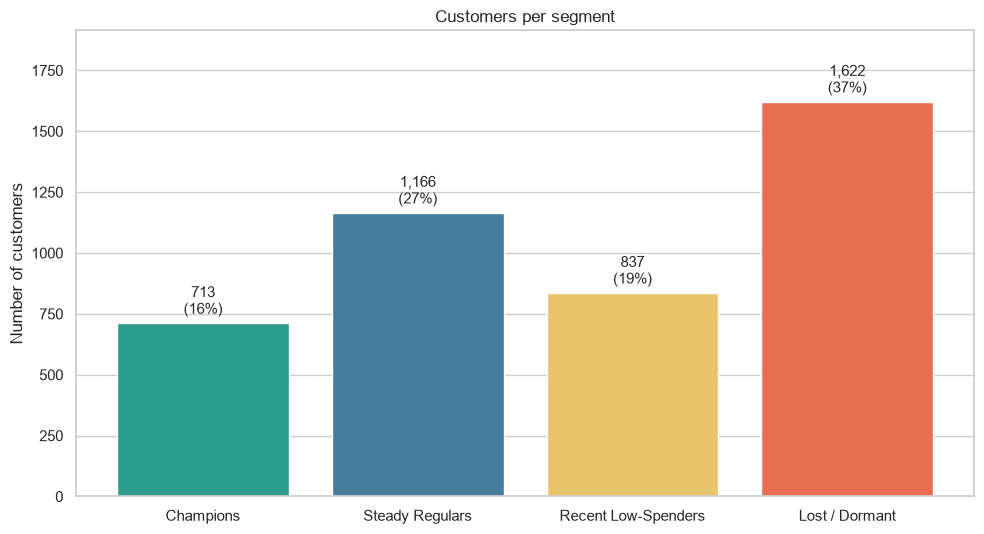

In [15]:
counts = rfm["Segment"].value_counts().reindex(order)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(counts.index, counts.values, color=[palette[s] for s in counts.index])
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + counts.max() * 0.012,
            f"{n:,}\n({n / len(rfm):.0%})", ha="center", va="bottom", fontsize=11)
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel("Number of customers")
ax.set_title("Customers per segment")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## Step 9 · Insights and recommended marketing actions

*(Figures below come from the run in this notebook, rounded.)*

### 1. Champions: about 16% of customers, about 65% of revenue
Average of ~14 orders and ~£8,100 spend, last order ~12 days ago.
**Action:** protect and reward them. Set up a VIP / loyalty tier, give early access to new products, and assign personal account management. Don't waste margin on discounts, because they already buy. Instead ask for referrals and reviews. Losing even a few of these customers would hurt more than any other segment.

### 2. Steady Regulars: about 27% of customers, about 24% of revenue
Average of ~4 orders and ~£1,800 spend, last order ~72 days ago.
**Action:** re-engage them *before* they drift away. Send reminder emails around the 60-day mark, suggest products related to past orders, and offer bundle or volume deals. Use tiered rewards ("spend a little more to unlock free delivery or a bulk discount") to nudge the best of them toward Champion behaviour. This segment has the most upside.

### 3. Recent Low-Spenders: about 19% of customers, about 5% of revenue
Average of ~2 orders and ~£560 spend, last order ~18 days ago.
**Action:** turn early interest into a habit. Run a welcome and onboarding email series, recommend products based on what they first bought, and offer a small incentive on the next order to secure the repeat purchase. Use minimum-spend thresholds to grow basket size.

### 4. Lost / Dormant: about 37% of customers, about 6% of revenue
Average of ~1.3 orders and ~£340 spend, last order ~180 days ago.
**Action:** run one low-cost win-back campaign ("we miss you" plus a time-limited offer, or a short survey about why they left). If they don't respond, stop spending on them. They are the biggest group but bring the least value, so effort is better spent on segments 1 to 3.

### Overall takeaway
Revenue is highly concentrated, so **retention of Champions and Steady Regulars should come first**, followed by converting Recent Low-Spenders into repeat buyers, with only minimal spend on Lost / Dormant customers.

### Limitations to keep in mind
- Only about 4,300 customers could be segmented. Rows with no `CustomerID` (about 25% of the data) had to be excluded.
- Data covers one year, so seasonal buying (e.g. pre-Christmas gift orders) can influence Recency and Frequency.
- K-Means assumes roughly round clusters and needs K chosen up front. K = 3 or K = 5 are also defensible and could be compared.
- Segment names are our interpretation of the numbers; check them against what the business knows about its customers.